# 데이터 증강 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week10/data_augmentation/lab/data_augmentation.ipynb)

뜻은 그대로, 모양만 바꿔 학습 데이터를 늘린다.

- **파트 1**: numpy 로 뒤집기 · 밀기 · 밝기 직접 만들기, torchvision 과 비교
- **파트 2**: 손글씨 100장: 증강 없음 vs 증강
- **파트 3**: 너무 센 증강 (180도 돌리기)

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 · 3 은 몇 분 걸린다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets, transforms as T

In [ ]:
tr = datasets.MNIST("data", train=True, download=True); te = datasets.MNIST("data", train=False, download=True)
Xte = te.data.float().div(255).unsqueeze(1); yte = te.targets
img = tr.data[0].numpy() / 255
print("label:", tr.targets[0].item())

**예상 결과**

```
label: 5
```

## 파트 1. 직접 만드는 증강

In [ ]:
def flip_lr(image):
    return None  # TODO: mirror left-right

def shift(image, dx, dy):
    out = np.zeros_like(image)
    h, w = image.shape
    out[max(dy, 0):h + min(dy, 0), max(dx, 0):w + min(dx, 0)] = image[max(-dy, 0):h + min(-dy, 0), max(-dx, 0):w + min(-dx, 0)]
    return out

def brightness(image, factor):
    return np.clip(image * factor, 0, 1)

aug_rand = T.RandomAffine(degrees=10, translate=(2 / 28, 2 / 28))
torch.manual_seed(0)
views = [img, flip_lr(img), shift(img, 2, -2), brightness(img, 0.5)] + [aug_rand(torch.tensor(img).unsqueeze(0))[0].numpy() for _ in range(4)]
titles = ["original", "flip", "shift", "dim"] + ["random affine"] * 4
fig, axs = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, v, t in zip(axs, views, titles):
    ax.imshow(v, cmap="gray_r", vmin=0, vmax=1); ax.set_title(t, fontsize=9); ax.axis("off")
plt.show()

**예상 결과**

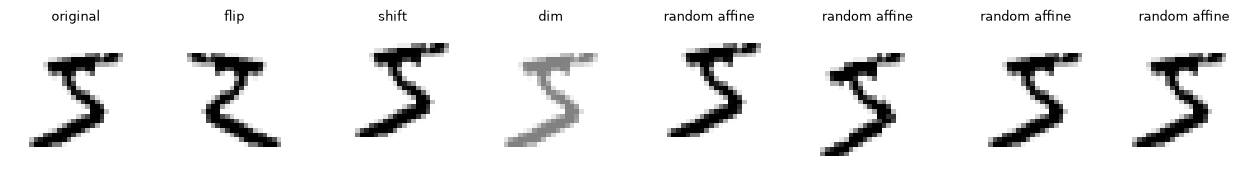

## 파트 2. 손글씨 100장

숫자마다 10장씩 100장만 학습. 작은 CNN, 400 에폭 (한 에폭 = 100장 전체 한 번).

In [ ]:
def small_cnn():
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(32 * 49, 64), nn.ReLU(), nn.Linear(64, 10))

rs = np.random.RandomState(0)
idx = np.concatenate([rs.choice(np.where(tr.targets.numpy() == c)[0], 10, replace=False) for c in range(10)])
X = tr.data[idx].float().div(255).unsqueeze(1); y = tr.targets[idx]

def run(X, y, augment, epochs=400, seed=0):
    torch.manual_seed(seed); net = small_cnn(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(epochs):
        xb = None  # TODO: a freshly augmented copy every epoch (or X itself if augment is None)
        opt.zero_grad(); F.cross_entropy(net(xb), y).backward(); opt.step()
    with torch.no_grad():
        return (net(Xte).argmax(1) == yte).float().mean().item()

print("no augmentation:", round(run(X, y, None), 3))
print("rotate ±10°, shift ±2:", round(run(X, y, T.RandomAffine(degrees=10, translate=(2 / 28, 2 / 28))), 3))

**예상 결과**

```
no augmentation: 0.775
rotate ±10°, shift ±2: 0.899
```

## 파트 3. 너무 센 증강

180도까지 마음대로 돌리면? (6 과 9 가 헷갈리기 시작한다)

In [ ]:
too_much = None  # TODO: rotate by any angle up to 180 degrees
print("rotate up to 180°:", round(run(X, y, too_much), 3))

**예상 결과**

```
rotate up to 180°: 0.746
```

**확인 질문**
1. 파트 1 의 좌우 뒤집기를 숫자에 써도 될까? 어떤 숫자가 문제가 될까?
2. 파트 2 에서 증강으로 정답률이 얼마나 올랐나? 학습 데이터를 1,000장으로 늘리면 증강의 효과는 커질까 작아질까?
3. 파트 3 의 결과가 증강 없음보다도 나쁘다면 왜일까?
4. 시험 데이터 `Xte` 에도 증강을 해야 할까?

데이터 출처: LeCun, Cortes, Burges, MNIST (torchvision) · Krizhevsky, Sutskever, Hinton (2012).